In [1]:
# Chit 11: Fashion-MNIST FNN: clothing predictions
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt

In [2]:
# Step 2: Load and prepare Fashion-MNIST
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
image_shape = (28, 28, 1)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step


In [3]:
# Step 3: Flatten the images
X_train = X_train.reshape(len(X_train), 784)
X_test = X_test.reshape(len(X_test), 784)

In [4]:
# Step 4: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [5]:
# Step 5: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
# Step 6: Prepare and run the model
model.fit(X_train, y_train, epochs=15, batch_size=128, verbose=0)

In [7]:
# Step 7: Predict test images
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

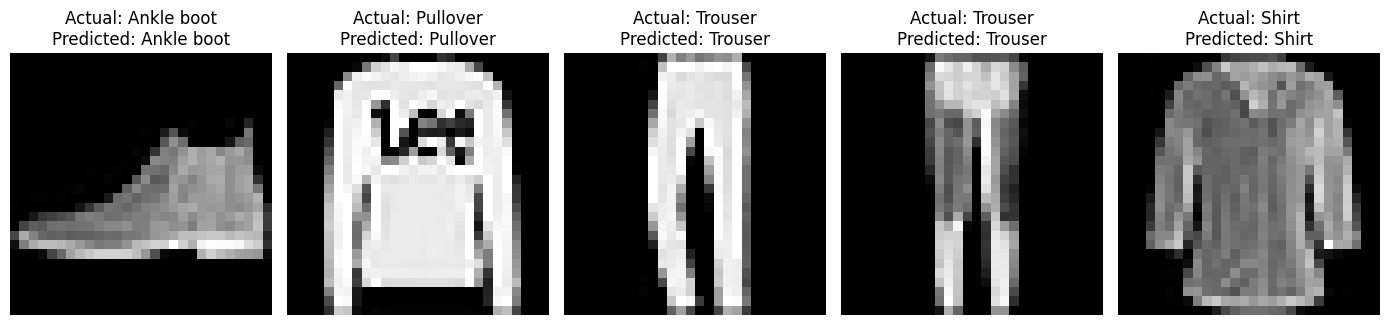

In [8]:
# Step 8: Show five examples
plt.figure(figsize=(14, 4))
for i in range(5):
    image = X_test[i].reshape(image_shape)
    plt.subplot(1, 5, i + 1)
    if image_shape[-1] == 1:
        plt.imshow(image.squeeze(), cmap="gray")
    else:
        plt.imshow(image)
    plt.title(f"Actual: {class_names[int(y_test[i])]}\nPredicted: {class_names[int(y_pred[i])]}")
    plt.axis("off")
plt.tight_layout()
plt.show()